# Early Identification of At-Risk Students in Distance Education (OULAD)
**Domain:** Education / Learning Analytics  **Task:** Binary classification — will a student *Fail or Withdraw* (at-risk = 1) or *Pass / earn Distinction* (0)?
**Dataset:** Open University Learning Analytics Dataset (OULAD), Kuzilek et al., *Scientific Data*, 2017 — 32,593 student-module records, CC-BY 4.0, from the UCI repository / Open University.
**Paradigms compared:** Traditional ML (scikit-learn) vs Deep Learning (TensorFlow/Keras with `tf.data`).

| Deliverable | Link |
|---|---|
| GitHub repository | `[PASTE LINK]` |
| Google Drive folder | `[PASTE LINK]` |
| Presentation video | `[PASTE LINK]` |

**Early-warning framing.** Predicting the outcome using the whole course is of little use, because by then the result is known. We therefore only use information available up to day `CUTOFF_DAY` of the course (default 60) and drop students who had already unregistered before that day. This keeps the problem realistic and prevents label leakage.

## 1. Setup, configuration and reproducibility
All paths and key settings live in one cell. Random seeds are fixed for Python, NumPy, scikit-learn and TensorFlow so that the notebook can be re-run top-to-bottom with the same results. `FAST_MODE=True` shrinks the hyper-parameter searches for a quick smoke test; set it to `False` for the final results you report.

In [1]:
%pip install -q wandb

In [2]:
import os, sys, random, time, json, warnings, shutil
warnings.filterwarnings("ignore")

SEED = 42
CUTOFF_DAY = 60        # early-warning horizon (days after course start); try 30 / 60 / 90
MAX_CUTOFF = 90        # largest cutoff used anywhere (keeps studentVle small in memory)
FAST_MODE = False      # True = tiny searches for debugging only

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    IN_COLAB = False

# Put the 5 OULAD CSVs (assessments, studentAssessment, studentInfo, studentRegistration, studentVle) in DATA_DIR
DATA_DIR = os.environ.get("OULAD_DATA_DIR", "/content/drive/MyDrive/OULAD_data" if IN_COLAB else "./data")
OUT_DIR  = os.environ.get("OULAD_OUT_DIR",  "/content/drive/MyDrive/OULAD_ML_Final_Project" if IN_COLAB else "./outputs")
for sub in ["models", "figures", "tb_logs", "wandb"]:
    os.makedirs(f"{OUT_DIR}/{sub}", exist_ok=True)

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["WANDB_MODE"] = "offline"          # logs saved locally, no account needed
os.environ["WANDB_DIR"] = f"{OUT_DIR}/wandb"
random.seed(SEED)
import numpy as np
np.random.seed(SEED)
print("Colab:", IN_COLAB, "| data:", DATA_DIR, "| out:", OUT_DIR)

Mounted at /content/drive
Colab: True | data: /content/drive/MyDrive/OULAD_data | out: /content/drive/MyDrive/OULAD_ML_Final_Project


**Output check.** Drive is mounted and the notebook reads the five OULAD CSV files from `MyDrive/OULAD_data`, writing models, figures and logs to `MyDrive/OULAD_ML_Final_Project`. All seeds are fixed to 42, so re-running top to bottom reproduces the same splits and results.

## 2. Imports


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, precision_recall_curve, average_precision_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

In [4]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()   # makes GPU runs repeatable (slightly slower)
except Exception as e:
    print("op determinism not enabled:", e)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


**Output check.** TensorFlow 2.21.0 loaded. Op determinism is enabled, so the neural-network results are repeatable on a GPU, at a small cost in speed.

## 3. Data loading
OULAD is a relational dataset. We load five tables: `studentInfo` (demographics + outcome), `studentRegistration`, `assessments`, `studentAssessment` (scores), and `studentVle` (about 10 million daily click records). Only VLE rows up to `MAX_CUTOFF` are kept, which makes the big table manageable in Colab memory. `?` values are read as missing.

In [5]:
KEY = ["code_module", "code_presentation", "id_student"]

def load_tables(data_dir, max_day):
    p = lambda f: os.path.join(data_dir, f)
    t = {
        "info": pd.read_csv(p("studentInfo.csv"), na_values=["?"]),
        "reg":  pd.read_csv(p("studentRegistration.csv"), na_values=["?"]),
        "ass":  pd.read_csv(p("assessments.csv"), na_values=["?"]),
        "sa":   pd.read_csv(p("studentAssessment.csv"), na_values=["?"]),
    }
    vle = pd.read_csv(p("studentVle.csv"),
                      usecols=["code_module", "code_presentation", "id_student", "date", "sum_click"],
                      dtype={"code_module": "category", "code_presentation": "category",
                             "id_student": "int32", "date": "int16", "sum_click": "int16"})
    vle = vle[vle["date"] <= max_day].copy()
    vle["code_module"] = vle["code_module"].astype(str)
    vle["code_presentation"] = vle["code_presentation"].astype(str)
    t["vle"] = vle
    return t

tables = load_tables(DATA_DIR, MAX_CUTOFF)
for k, v in tables.items():
    print(f"{k:5s} {v.shape}")
RAW_ROWS = len(tables["info"])
print("Raw student records (studentInfo):", RAW_ROWS, "(requirement: >= 20,000)")

info  (32593, 12)
reg   (32593, 5)
ass   (206, 6)
sa    (173912, 5)
vle   (5486878, 5)
Raw student records (studentInfo): 32593 (requirement: >= 20,000)


**Interpretation.** `studentInfo` has 32,593 student-module records, well above the 20,000-row requirement. After keeping only days ≤ 90, `studentVle` drops from about 10.6 million to 5,486,878 click rows, which keeps memory manageable in Colab. There are 206 assessments and 173,912 assessment submissions. One student can appear in several modules, which is why Section 6 splits by student rather than by row.

## 4. Exploratory data analysis
Before modelling we look at the target distribution and how a few key variables relate to it. This shapes the feature engineering and the choice of evaluation metrics.

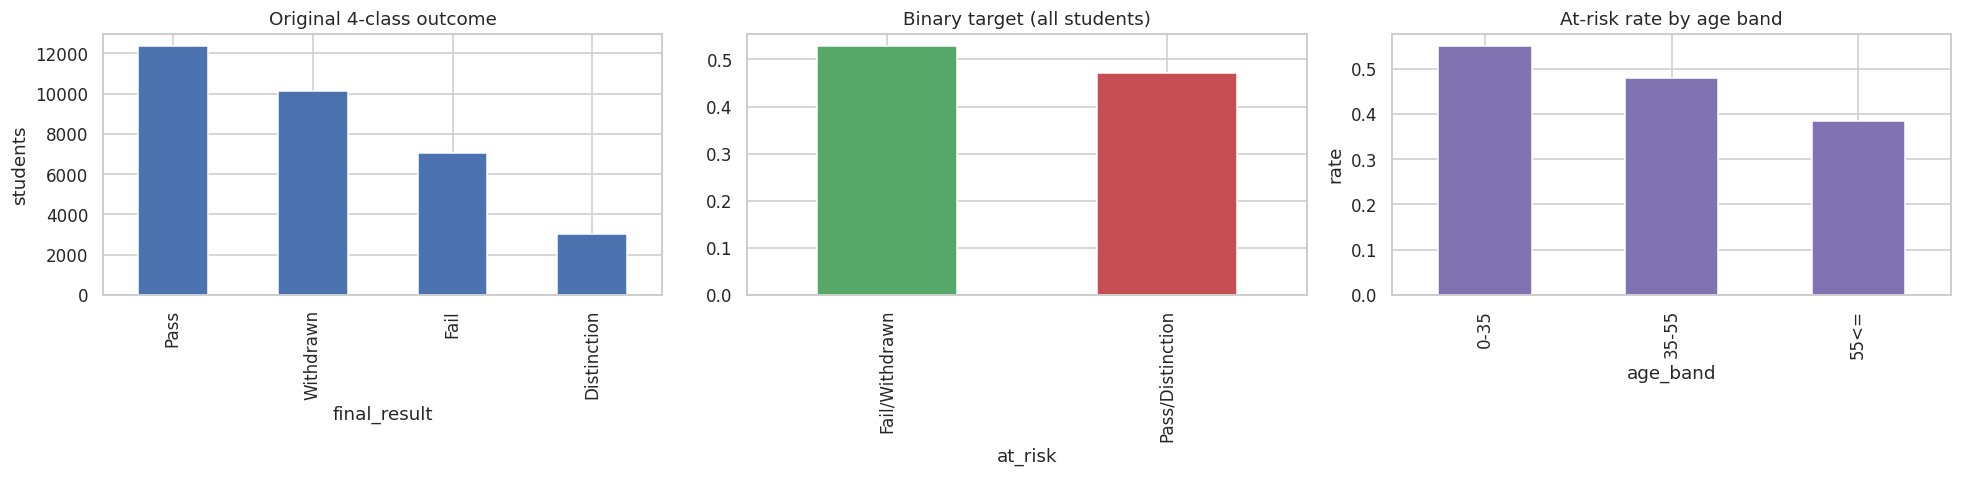

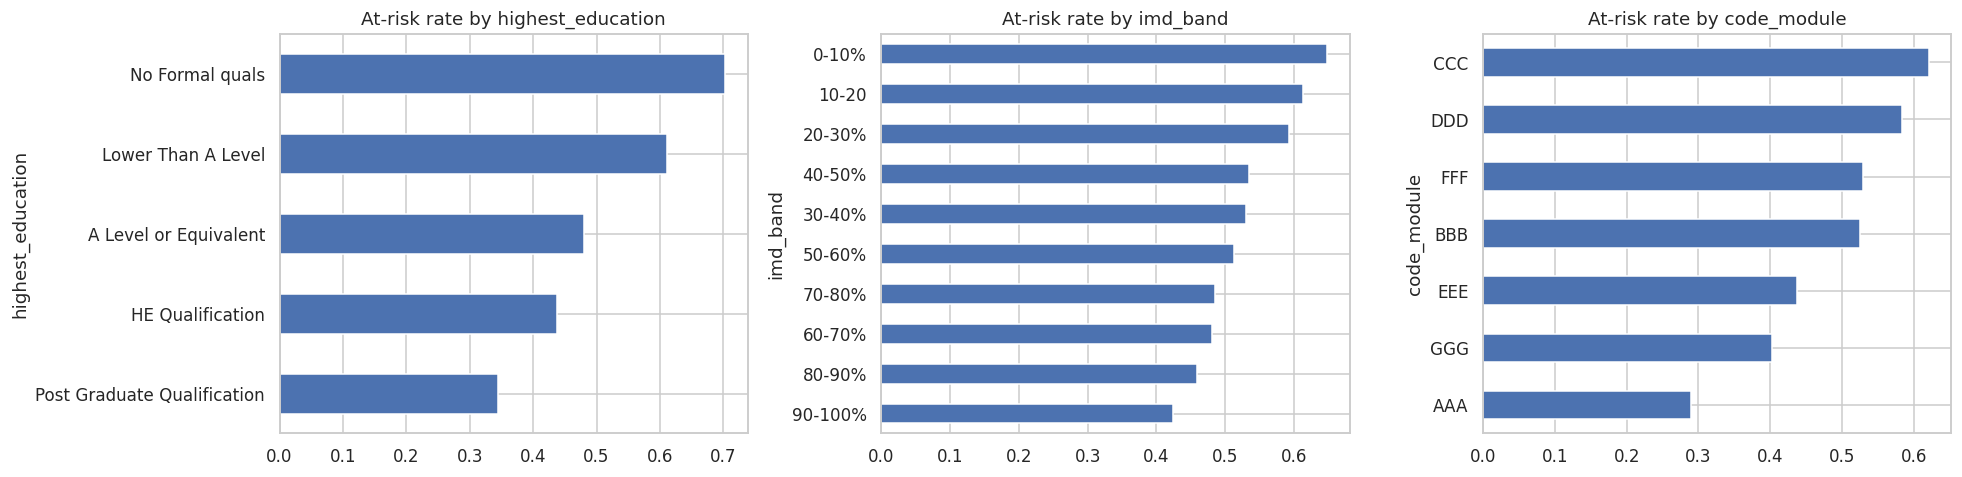

imd_band    1111
Name: missing values, dtype: int64


In [6]:
info = tables["info"].copy()
info["at_risk"] = info["final_result"].isin(["Fail", "Withdrawn"]).astype(int)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
info["final_result"].value_counts().plot.bar(ax=ax[0], color="#4c72b0"); ax[0].set_title("Original 4-class outcome"); ax[0].set_ylabel("students")
info["at_risk"].value_counts(normalize=True).rename({0: "Pass/Distinction", 1: "Fail/Withdrawn"}).plot.bar(ax=ax[1], color=["#55a868", "#c44e52"]); ax[1].set_title("Binary target (all students)")
info.groupby("age_band")["at_risk"].mean().plot.bar(ax=ax[2], color="#8172b2"); ax[2].set_title("At-risk rate by age band"); ax[2].set_ylabel("rate")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/eda_target.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, c in zip(ax, ["highest_education", "imd_band", "code_module"]):
    info.groupby(c)["at_risk"].mean().sort_values().plot.barh(ax=a, color="#4c72b0"); a.set_title(f"At-risk rate by {c}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/eda_categorical.png", dpi=200); plt.show()
print(info.isna().sum()[info.isna().sum() > 0].rename("missing values"))

**Interpretation.** Across all 32,593 records, 52.8 % end in Fail (7,052) or Withdrawn (10,156), so the full dataset is roughly balanced. Withdrawal is the second most common outcome after Pass, which shows how large the attrition problem is. The at-risk rate falls with age (about 55 % for under-35s versus about 38 % for over-55s) and differs by highest education, IMD band and module, so demographics carry some signal on their own (tested in E8a). `imd_band` is the only column with missing values (1,111), which are kept as an `Unknown` category rather than dropped. *(Note: in the middle plot the colours are swapped — the green bar is Fail/Withdrawn.)*

## 5. Feature engineering (early-warning features)
For each student-module record we build behavioural features from data available **up to `cutoff` days** after the course starts:

* **Engagement (VLE):** total clicks, number of active days, click events, peak daily clicks, pre-course clicks, clicks in the first vs second half of the window, and their difference (`click_trend`, a measure of disengagement), plus clicks per active day.
* **Assessment:** number of assessments submitted, mean/min score, weight-adjusted score, number of late submissions, average days late and late ratio.
* **Registration/demographics:** registration date, previous attempts, credits, education, deprivation band (IMD), age band, region, gender, disability, module and presentation.

Students who unregistered on or before the cutoff are removed (their outcome is already known). `date_unregistration` is never used as a feature because it directly reveals the label.

In [7]:
def build_features(t, cutoff):
    df = t["info"].merge(t["reg"], on=KEY, how="left")
    df = df[~(df["date_unregistration"] <= cutoff)].copy()          # already withdrawn before the cutoff

    v = t["vle"][t["vle"]["date"] <= cutoff]
    g = v.groupby(KEY).agg(total_clicks=("sum_click", "sum"), active_days=("date", "nunique"),
                           click_events=("sum_click", "size"), max_daily_clicks=("sum_click", "max")).reset_index()
    half = cutoff // 2
    for name, mask in [("pre_start_clicks", v["date"] < 0),
                       ("clicks_first_half", (v["date"] >= 0) & (v["date"] <= half)),
                       ("clicks_second_half", (v["date"] > half))]:
        s = v[mask].groupby(KEY)["sum_click"].sum().rename(name).reset_index()
        g = g.merge(s, on=KEY, how="left")
    df = df.merge(g, on=KEY, how="left")

    a = t["sa"].merge(t["ass"], on="id_assessment")
    a = a[a["date_submitted"] <= cutoff].copy()
    a["days_late"] = (a["date_submitted"] - a["date"]).clip(lower=0)
    a["is_late"] = (a["date_submitted"] > a["date"]).astype(int)
    a["w"] = a["weight"].fillna(0)
    a["w_score"] = a["score"] * a["w"]
    ag = a.groupby(KEY[:2] + ["id_student"]).agg(n_assessments=("id_assessment", "count"), mean_score=("score", "mean"),
            min_score=("score", "min"), sum_w=("w", "sum"), sum_ws=("w_score", "sum"), n_late=("is_late", "sum"),
            mean_days_late=("days_late", "mean")).reset_index()
    ag["weighted_score"] = ag["sum_ws"] / ag["sum_w"].replace(0, np.nan)
    df = df.merge(ag.drop(columns=["sum_ws", "sum_w"]), on=KEY, how="left")

    zero_fill = ["total_clicks", "active_days", "click_events", "max_daily_clicks", "pre_start_clicks",
                 "clicks_first_half", "clicks_second_half", "n_assessments", "n_late"]
    df[zero_fill] = df[zero_fill].fillna(0)
    df["clicks_per_active_day"] = df["total_clicks"] / df["active_days"].replace(0, np.nan)
    df["late_ratio"] = df["n_late"] / df["n_assessments"].replace(0, np.nan)
    df["click_trend"] = df["clicks_second_half"] - df["clicks_first_half"]
    df["at_risk"] = df["final_result"].isin(["Fail", "Withdrawn"]).astype(int)
    return df.drop(columns=["date_unregistration"]).reset_index(drop=True)

df = build_features(tables, CUTOFF_DAY)
print(f"Modelling table at day {CUTOFF_DAY}: {df.shape}  |  at-risk rate = {df['at_risk'].mean():.3f}")
df.head()

Modelling table at day 60: (26361, 30)  |  at-risk rate = 0.416


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,n_assessments,mean_score,min_score,n_late,mean_days_late,weighted_score,clicks_per_active_day,late_ratio,click_trend,at_risk
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,2.0,81.5,78.0,0.0,0.0,82.666667,29.388889,0.0,-221.0,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,2.0,69.0,68.0,1.0,1.5,68.666667,25.730769,0.5,-352.0,0
2,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,2.0,71.5,71.0,0.0,0.0,71.333333,19.902439,0.0,-95.0,0
3,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,1.0,69.0,69.0,1.0,7.0,69.000000,21.607143,1.0,-234.0,0
4,AAA,2013J,38053,M,Wales,A Level or Equivalent,80-90%,35-55,0,60,...,1.0,79.0,79.0,0.0,0.0,79.000000,20.510204,0.0,-178.0,0


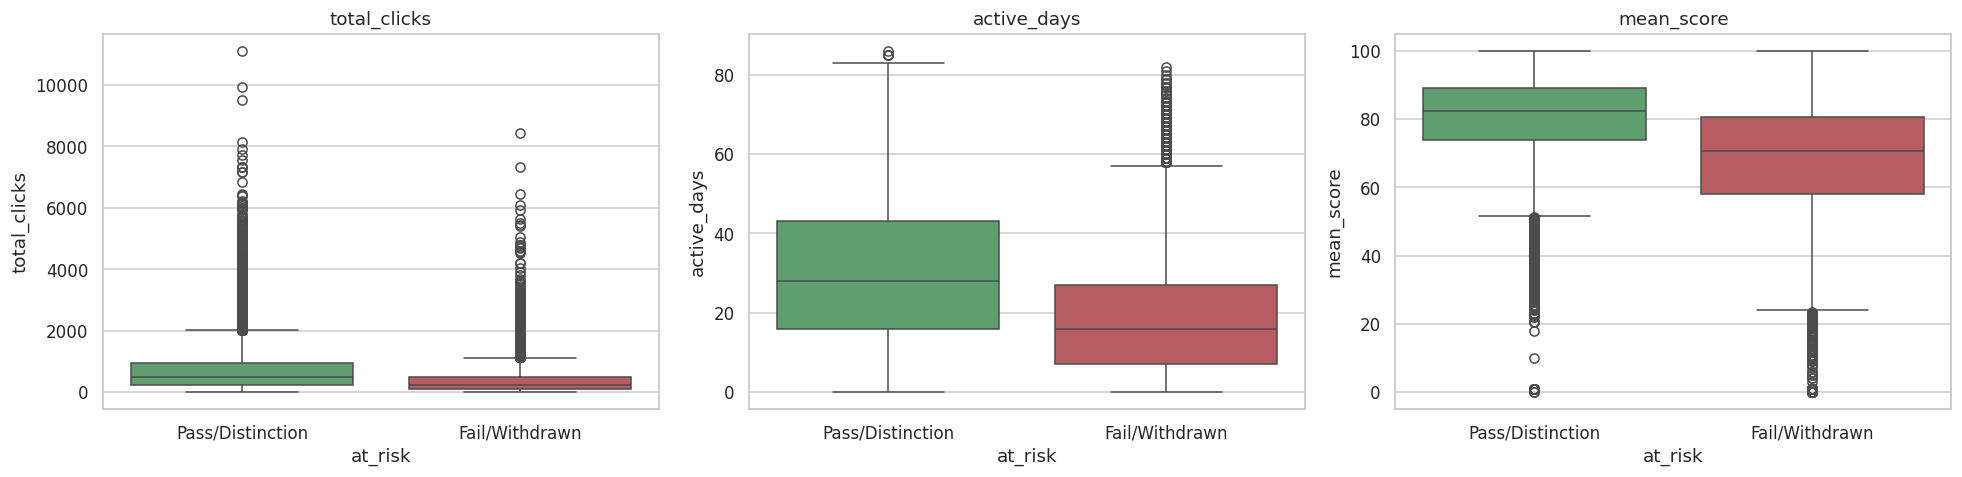

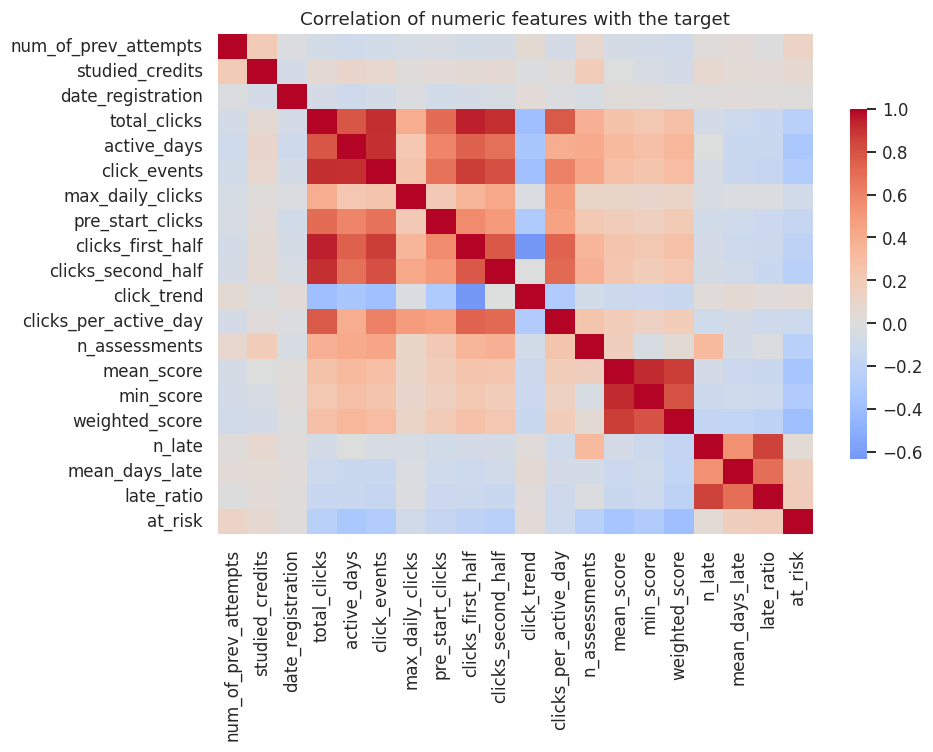

In [8]:
CAT = ["code_module", "code_presentation", "gender", "region", "highest_education", "imd_band", "age_band", "disability"]
DEMO_NUM = ["num_of_prev_attempts", "studied_credits", "date_registration"]
VLE_NUM = ["total_clicks", "active_days", "click_events", "max_daily_clicks", "pre_start_clicks",
           "clicks_first_half", "clicks_second_half", "click_trend", "clicks_per_active_day"]
ASSESS_NUM = ["n_assessments", "mean_score", "min_score", "weighted_score", "n_late", "mean_days_late", "late_ratio"]
NUM = DEMO_NUM + VLE_NUM + ASSESS_NUM
ALL_FEATURES = CAT + NUM

# Quick look at how engagement separates the classes
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, c in zip(ax, ["total_clicks", "active_days", "mean_score"]):
    sns.boxplot(data=df, x="at_risk", y=c, hue="at_risk", legend=False, ax=a, palette=["#55a868", "#c44e52"])
    a.set_xticklabels(["Pass/Distinction", "Fail/Withdrawn"]); a.set_title(c)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/eda_features.png", dpi=200); plt.show()
plt.figure(figsize=(9, 7)); sns.heatmap(df[NUM + ["at_risk"]].corr(), cmap="coolwarm", center=0, cbar_kws={"shrink": .7})
plt.title("Correlation of numeric features with the target"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/eda_corr.png", dpi=200); plt.show()

**Interpretation.** At day 60 the modelling table has 26,361 records: 6,232 students who had already withdrawn were removed, and the at-risk rate drops from 52.8 % to 41.6 %. The boxplots show that at-risk students have far fewer total clicks and active days, and lower mean scores, than students who pass. The heatmap shows the click features are strongly correlated with each other (`total_clicks`, `click_events`, `active_days`). This does not hurt tree models, but it means permutation importance in Section 16 spreads credit across these features and understates each one.

## 6. Train / validation / test split (grouped by student)
The same `id_student` can appear in several modules. If those rows were split randomly, the same person could appear in both training and test data and inflate scores. We therefore split **by student** (70 % train / 15 % validation / 15 % test). Each student is assigned to a split once using a seeded shuffle, so every cutoff variant used later keeps the *same* students in the *same* split. Model selection uses the validation set; the test set is only used for final reporting.

In [9]:
rng = np.random.RandomState(SEED)
all_ids = np.sort(tables["info"]["id_student"].unique())
rng.shuffle(all_ids)
n = len(all_ids)
split_of = {}
for i in all_ids[: int(.70 * n)]: split_of[i] = "train"
for i in all_ids[int(.70 * n): int(.85 * n)]: split_of[i] = "val"
for i in all_ids[int(.85 * n):]: split_of[i] = "test"

def make_splits(d):
    s = d["id_student"].map(split_of)
    return {k: d[s == k].reset_index(drop=True) for k in ["train", "val", "test"]}

S = make_splits(df)
X_train, y_train, g_train = S["train"][ALL_FEATURES], S["train"]["at_risk"].values, S["train"]["id_student"].values
X_val,   y_val   = S["val"][ALL_FEATURES],   S["val"]["at_risk"].values
X_test,  y_test  = S["test"][ALL_FEATURES],  S["test"]["at_risk"].values
SPLIT_DESC = f"70/15/15 by student ({len(X_train)}/{len(X_val)}/{len(X_test)})"
print(SPLIT_DESC)
print("At-risk rate  train/val/test:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))
assert not set(S["train"]["id_student"]) & set(S["test"]["id_student"]), "student leakage!"

70/15/15 by student (18417/3951/3993)
At-risk rate  train/val/test: 0.414 0.417 0.425


**Interpretation.** The split gives 18,417 / 3,951 / 3,993 records. At-risk rates in train, validation and test are 0.414, 0.417 and 0.425, so the splits are well balanced; the test set is marginally harder, which partly explains why every model scores about 0.02 AUC lower on test than on validation. The assertion confirms no student appears in both training and test.

## 7. Preprocessing pipeline
Numeric features: median imputation (robust to the heavy right skew of click counts), with *missing-indicator* columns because "no assessment submitted yet" is itself informative, followed by standardisation. Categorical features: constant imputation (`Unknown`) and one-hot encoding. The `ColumnTransformer` is fitted **only on the training split** and sits inside every scikit-learn `Pipeline`, so cross-validation never leaks statistics from held-out folds.

In [10]:
def make_preprocessor(num_cols, cat_cols):
    num_t = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())])
    cat_t = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    parts = []
    if num_cols: parts.append(("num", num_t, num_cols))
    if cat_cols: parts.append(("cat", cat_t, cat_cols))
    return ColumnTransformer(parts)

def make_pipe(clf, num_cols=NUM, cat_cols=CAT):
    return Pipeline([("prep", make_preprocessor(num_cols, cat_cols)), ("clf", clf)])

# Preprocessed arrays for the deep learning models (fitted on train only)
dl_prep = make_preprocessor(NUM, CAT)
Xtr = dl_prep.fit_transform(X_train).astype("float32")
Xva = dl_prep.transform(X_val).astype("float32")
Xte = dl_prep.transform(X_test).astype("float32")
print("Preprocessed feature matrix:", Xtr.shape)

Preprocessed feature matrix: (18417, 73)


**Interpretation.** After median imputation, missing-value indicators and one-hot encoding, each record has 73 input columns. The preprocessor is fitted on the 18,417 training records only, so validation and test data never influence the medians, scaling or categories.

## 8. Experiment tracking utilities
Every experiment is recorded in a master table (model, hyper-parameters, features, split, validation and test metrics, a training-vs-validation gap for bias/variance analysis, and an observation) **and** logged to Weights & Biases in offline mode, which writes run files to `OUT_DIR/wandb` so each row in the table is traceable to a logged run. Deep learning runs additionally write TensorBoard logs to `OUT_DIR/tb_logs` (view with `%load_ext tensorboard` and `%tensorboard --logdir <path>`).

Metrics are computed at the default 0.5 threshold for the table; ROC-AUC and average precision are threshold-free. Because the target is only mildly imbalanced (about 40 % positive), accuracy is meaningful, but **recall** on the at-risk class is the most important metric for an early-warning system, because a missed student cannot be helped.

In [11]:
try:
    import wandb
    HAS_WANDB = True
except Exception:
    HAS_WANDB = False

def wb_start(name, config):
    if HAS_WANDB:
        try: wandb.init(project="oulad-at-risk", name=name, config=config, reinit=True, mode="offline")
        except Exception as e: print("wandb disabled:", e)
def wb_log(d):
    if HAS_WANDB and wandb.run is not None: wandb.log(d)
def wb_end():
    if HAS_WANDB and wandb.run is not None: wandb.finish(quiet=True)

RESULTS, STORE, HISTORIES = [], {}, {}      # RESULTS -> master table, STORE -> fitted models and predictions

def metrics_at(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return dict(Acc=accuracy_score(y, yhat), Prec=precision_score(y, yhat, zero_division=0),
                Rec=recall_score(y, yhat, zero_division=0), F1=f1_score(y, yhat, zero_division=0),
                AUC=roc_auc_score(y, p), AP=average_precision_score(y, p))

def log_experiment(exp_id, name, paradigm, params, features, model, p_train, p_val, p_test,
                   y_tr, y_va, y_te, seconds, main=True, obs="(write your interpretation)", split=None):
    mt, mv, ms = metrics_at(y_tr, p_train), metrics_at(y_va, p_val), metrics_at(y_te, p_test)
    row = {"ID": exp_id, "Model": name, "Paradigm": paradigm, "Hyperparameters": str(params), "Features": features,
           "Split": split or SPLIT_DESC, "Train AUC": round(mt["AUC"], 4), "Val AUC": round(mv["AUC"], 4),
           "Gap (train-val)": round(mt["AUC"] - mv["AUC"], 4), "Test Acc": round(ms["Acc"], 4),
           "Test Prec": round(ms["Prec"], 4), "Test Rec": round(ms["Rec"], 4), "Test F1": round(ms["F1"], 4),
           "Test AUC": round(ms["AUC"], 4), "Test AP": round(ms["AP"], 4), "Fit s": round(seconds, 1),
           "Main": main, "Observation": obs}
    RESULTS.append(row)
    STORE[exp_id] = dict(model=model, p_train=p_train, p_val=p_val, p_test=p_test, paradigm=paradigm, main=main)
    print(f"[{exp_id}] {name:34s} val AUC {mv['AUC']:.4f} | test AUC {ms['AUC']:.4f} | test rec {ms['Rec']:.3f} | gap {mt['AUC']-mv['AUC']:+.3f}")
    return row

def run_sklearn(exp_id, name, estimator, params, features="all", num_cols=NUM, cat_cols=CAT, fit_kwargs=None,
                data=None, main=True, split=None):
    # Fit a scikit-learn pipeline, log it, and store predictions. 'data' lets ablations/cutoffs swap in other splits.
    d = data or dict(Xtr=X_train, ytr=y_train, Xva=X_val, yva=y_val, Xte=X_test, yte=y_test)
    wb_start(exp_id, {"model": name, **{k: str(v) for k, v in params.items()}, "features": features})
    t0 = time.time()
    pipe = make_pipe(estimator, num_cols, cat_cols)
    pipe.fit(d["Xtr"], d["ytr"], **(fit_kwargs or {}))
    sec = time.time() - t0
    pr = lambda X: pipe.predict_proba(X)[:, 1]
    row = log_experiment(exp_id, name, "Traditional ML", params, features, pipe, pr(d["Xtr"]), pr(d["Xva"]), pr(d["Xte"]),
                         d["ytr"], d["yva"], d["yte"], sec, main, split=split)
    wb_log({k: v for k, v in row.items() if isinstance(v, (int, float))}); wb_end()
    return pipe

**Note.** This cell only defines helper functions, so it prints nothing. From here on, every experiment adds one row to the master table (Section 12) and one offline W&B run in `OUT_DIR/wandb`, so each reported number is traceable to a logged run. The W&B deprecation warnings below are harmless.

## 9. Experiments — Traditional machine learning (scikit-learn)
We go from simple to complex, and each experiment is motivated by what the previous one showed.

* **E1 – Logistic Regression baseline.** A linear, interpretable reference. If complex models cannot beat it, the extra complexity is not justified.
* **E2 – Logistic Regression tuned** (C, class weights) with grouped 3-fold cross-validation, to see how much tuning alone helps a linear model.
* **E3 / E4 – Random Forest** default vs. tuned: depth, leaf size and `max_features` control the bias–variance trade-off of the ensemble.
* **E5 / E6 – Histogram Gradient Boosting** default vs. tuned: sequential boosting usually wins on tabular data, learning rate and tree size control over-fitting.
* **E7 – Calibrated linear SVM** (maximum-margin classifier; sigmoid calibration gives probabilities for ROC-AUC).

In [12]:
cv = GroupKFold(n_splits=3)
N_ITER = 4 if FAST_MODE else 12

# E1 - baseline
run_sklearn("E1", "Logistic Regression (baseline)", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
            {"C": 1.0, "penalty": "l2"})

# E2 - tuned logistic regression
t0 = time.time()
gs = GridSearchCV(make_pipe(LogisticRegression(max_iter=2000, random_state=SEED)),
                  {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]},
                  scoring="roc_auc", cv=cv, n_jobs=-1)
gs.fit(X_train, y_train, groups=g_train)
best = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
print("E2 best params:", best, "| CV AUC:", round(gs.best_score_, 4))
run_sklearn("E2", "Logistic Regression (tuned)", LogisticRegression(max_iter=2000, random_state=SEED, **best),
            {**best, "search": "GridSearchCV 3-fold grouped"})

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


wandb: WARNING The `quiet` argument to `wandb.run.finish()` is deprecated, use `wandb.Settings(quiet=...)` to set this instead.


[E1] Logistic Regression (baseline)     val AUC 0.8417 | test AUC 0.8231 | test rec 0.599 | gap -0.011


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
Fit s,0.5


E2 best params: {'C': 1, 'class_weight': None} | CV AUC: 0.8276


[E2] Logistic Regression (tuned)        val AUC 0.8417 | test AUC 0.8231 | test rec 0.599 | gap -0.011


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
Fit s,1


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['num_of_prev_attempts',
                                                   'studied_credits',
                                                   'date_registration',
                                                   'total_clicks',
                                                   'active_days',
                                                   'click_events',
                                                   'max_daily_clicks',
                                                   'pre_start_clicks',
                                                   'clicks_first_half',
                                                   'clicks_second_half',...
                                                   'mean_days_late',
                                                   'late_ratio']),
                                                 ('cat',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('oh',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['code_module',
                                                   'code_presentation',
                                                   'gender', 'region',
                                                   'highest_education',
                                                   'imd_band', 'age_band',
                                                   'disability'])])),
                ('clf',
                 LogisticRegression(C=1, max_iter=2000, random_state=42))])

In [13]:
# E3 - random forest baseline
run_sklearn("E3", "Random Forest (default)", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
            {"n_estimators": 100, "max_depth": None})

# E4 - random forest tuned (randomised search)
rf_space = {"clf__n_estimators": [200, 400], "clf__max_depth": [6, 10, 15, None],
            "clf__min_samples_leaf": [1, 5, 10, 20], "clf__max_features": ["sqrt", 0.3]}
rs = RandomizedSearchCV(make_pipe(RandomForestClassifier(random_state=SEED, n_jobs=-1)), rf_space, n_iter=N_ITER,
                        scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=1)
rs.fit(X_train, y_train, groups=g_train)
best = {k.replace("clf__", ""): v for k, v in rs.best_params_.items()}
print("E4 best params:", best, "| CV AUC:", round(rs.best_score_, 4))
run_sklearn("E4", "Random Forest (tuned)", RandomForestClassifier(random_state=SEED, n_jobs=-1, **best),
            {**best, "search": f"RandomizedSearchCV n_iter={N_ITER}"})

[E3] Random Forest (default)            val AUC 0.8464 | test AUC 0.8166 | test rec 0.601 | gap +0.154


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
Fit s,3.8


E4 best params: {'n_estimators': 400, 'min_samples_leaf': 10, 'max_features': 0.3, 'max_depth': None} | CV AUC: 0.8289


[E4] Random Forest (tuned)              val AUC 0.8470 | test AUC 0.8204 | test rec 0.598 | gap +0.096


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
Fit s,27.5


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['num_of_prev_attempts',
                                                   'studied_credits',
                                                   'date_registration',
                                                   'total_clicks',
                                                   'active_days',
                                                   'click_events',
                                                   'max_daily_clicks',
                                                   'pre_start_clicks',
                                                   'clicks_first_half',
                                                   'clicks_second_half',...
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('oh',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['code_module',
                                                   'code_presentation',
                                                   'gender', 'region',
                                                   'highest_education',
                                                   'imd_band', 'age_band',
                                                   'disability'])])),
                ('clf',
                 RandomForestClassifier(max_features=0.3, min_samples_leaf=10,
                                        n_estimators=400, n_jobs=-1,
                                        random_state=42))])

In [14]:
# E5 - gradient boosting baseline
run_sklearn("E5", "Hist. Gradient Boosting (default)", HistGradientBoostingClassifier(random_state=SEED),
            {"learning_rate": 0.1, "max_iter": 100})

# E6 - gradient boosting tuned
gb_space = {"clf__learning_rate": [0.03, 0.05, 0.1], "clf__max_leaf_nodes": [8, 15, 31], "clf__max_iter": [150, 300],
            "clf__min_samples_leaf": [20, 50, 100], "clf__l2_regularization": [0.0, 1.0, 10.0]}
rs = RandomizedSearchCV(make_pipe(HistGradientBoostingClassifier(random_state=SEED)), gb_space, n_iter=N_ITER,
                        scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=1)
rs.fit(X_train, y_train, groups=g_train)
best = {k.replace("clf__", ""): v for k, v in rs.best_params_.items()}
print("E6 best params:", best, "| CV AUC:", round(rs.best_score_, 4))
run_sklearn("E6", "Hist. Gradient Boosting (tuned)", HistGradientBoostingClassifier(random_state=SEED, **best),
            {**best, "search": f"RandomizedSearchCV n_iter={N_ITER}"})

# E7 - calibrated linear SVM
run_sklearn("E7", "Linear SVM (calibrated)", CalibratedClassifierCV(LinearSVC(C=0.1, max_iter=5000, random_state=SEED), cv=3),
            {"C": 0.1, "calibration": "sigmoid, cv=3"})

[E5] Hist. Gradient Boosting (default)  val AUC 0.8505 | test AUC 0.8240 | test rec 0.600 | gap +0.040


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
Fit s,1.4


E6 best params: {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 150, 'learning_rate': 0.05, 'l2_regularization': 10.0} | CV AUC: 0.8335


[E6] Hist. Gradient Boosting (tuned)    val AUC 0.8520 | test AUC 0.8273 | test rec 0.607 | gap +0.004


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
Fit s,2.7


[E7] Linear SVM (calibrated)            val AUC 0.8372 | test AUC 0.8126 | test rec 0.561 | gap -0.013


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
Fit s,0.7


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['num_of_prev_attempts',
                                                   'studied_credits',
                                                   'date_registration',
                                                   'total_clicks',
                                                   'active_days',
                                                   'click_events',
                                                   'max_daily_clicks',
                                                   'pre_start_clicks',
                                                   'clicks_first_half',
                                                   'clicks_second_half',...
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('oh',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['code_module',
                                                   'code_presentation',
                                                   'gender', 'region',
                                                   'highest_education',
                                                   'imd_band', 'age_band',
                                                   'disability'])])),
                ('clf',
                 CalibratedClassifierCV(cv=3,
                                        estimator=LinearSVC(C=0.1,
                                                            max_iter=5000,
                                                            random_state=42)))])

**Interpretation.**
* **Logistic regression (E1, E2):** validation AUC 0.842. Grid search picked C = 1 and no class weighting — exactly the baseline — so E2 is identical to E1. The negative train–validation gap (−0.011) shows no over-fitting at all; the linear model is limited by bias, not variance.
* **Random forest (E3 → E4):** the default forest memorises the training set (train AUC 1.000, gap 0.154), the clearest case of high variance in the project. Requiring at least 10 samples per leaf and 30 % of features per split (E4) cut the gap to 0.096 but raised validation AUC only to 0.847.
* **Gradient boosting (E5 → E6):** the best traditional family. Tuning chose a lower learning rate (0.05), small trees (15 leaves), large leaves (100 samples) and strong L2 (10), which shrank the gap from 0.040 to 0.004 and raised validation AUC from 0.851 to 0.852 (test 0.824 → 0.827). The gain from tuning is small; its main effect was removing over-fitting.
* **Linear SVM (E7):** validation AUC 0.837, just below logistic regression, as expected for another linear classifier.

All seven models fall within 0.015 validation AUC of each other, which already suggests the features, not the algorithm, set the ceiling.

## 10. Feature-engineering ablation and early-warning horizon
Two further experiments test *why* the models work.

* **E8a/E8b – Feature groups.** Same gradient-boosting settings as E5 on (a) demographics only and (b) demographics + VLE engagement. Comparing with E5 (all features) shows how much the behavioural and assessment features add beyond who the student is.
* **E9a/E9b – Cutoff day.** The full pipeline is rebuilt with information up to day 30 and day 90 (the main experiments use `CUTOFF_DAY`). Later cutoffs give more evidence but less time to intervene. These rows use the same student-level split, but a slightly different population (students who left before the cutoff are excluded), so they are marked `Main = False` and are not used for choosing the best model.

In [15]:
HGB_DEFAULT = lambda: HistGradientBoostingClassifier(random_state=SEED)
run_sklearn("E8a", "HGB - demographics only", HGB_DEFAULT(), {"same as E5": True}, features="demographic + registration",
            num_cols=DEMO_NUM, cat_cols=CAT, main=False)
run_sklearn("E8b", "HGB - demographics + VLE clicks", HGB_DEFAULT(), {"same as E5": True}, features="demographic + VLE",
            num_cols=DEMO_NUM + VLE_NUM, cat_cols=CAT, main=False)

for cut in [30, 90]:
    d = build_features(tables, cut)
    sp = make_splits(d)
    data = dict(Xtr=sp["train"][ALL_FEATURES], ytr=sp["train"]["at_risk"].values,
                Xva=sp["val"][ALL_FEATURES],   yva=sp["val"]["at_risk"].values,
                Xte=sp["test"][ALL_FEATURES],  yte=sp["test"]["at_risk"].values)
    run_sklearn(f"E9_{cut}", f"HGB - cutoff day {cut}", HGB_DEFAULT(), {"cutoff_day": cut}, features=f"all, day<= {cut}",
                data=data, main=False, split=f"70/15/15 by student ({len(data['Xtr'])}/{len(data['Xva'])}/{len(data['Xte'])})")

[E8a] HGB - demographics only            val AUC 0.6608 | test AUC 0.6557 | test rec 0.347 | gap +0.056


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
Fit s,0.7


[E8b] HGB - demographics + VLE clicks    val AUC 0.7905 | test AUC 0.7837 | test rec 0.537 | gap +0.051


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
Fit s,1.1


[E9_30] HGB - cutoff day 30                val AUC 0.7942 | test AUC 0.7797 | test rec 0.580 | gap +0.064


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
Fit s,1.5


[E9_90] HGB - cutoff day 90                val AUC 0.8642 | test AUC 0.8513 | test rec 0.639 | gap +0.045


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
Fit s,1.3


**Interpretation.** Feature groups matter far more than algorithms. With demographics only (E8a), validation AUC is 0.661 and test recall only 0.347. Adding VLE engagement (E8b) raises AUC to 0.791, and adding early assessment features (E5) raises it to 0.851 — a gain of 0.19 AUC, more than ten times the spread between algorithms in Section 9. On the horizon, moving from day 30 (E9_30, 0.794) to day 60 adds 0.056 AUC, while moving on to day 90 (E9_90, 0.864) adds only 0.014. Most of the useful signal therefore arrives between days 30 and 60, when the first assessments are due, which makes day 60 a sensible point to intervene.

## 11. Experiments — Deep learning (TensorFlow / Keras with `tf.data`)
All deep models read data through a `tf.data` pipeline (shuffle → batch → prefetch). Class weights compensate for the mild imbalance. Every run gets its own fresh `EarlyStopping` callback (monitoring validation loss, restoring the best weights).

* **D1 – Baseline MLP** (Sequential, 64→32, no regularisation): shows how a plain network behaves.
* **D2 – Regularised MLP** (128→64→32 with batch normalisation, dropout and L2): tests whether regularisation narrows any train–validation gap.
* **D3 – Residual MLP (Functional API)** with an exponential learning-rate decay: tests skip connections and an LR schedule.
* **D4 – Systematic sweep** of learning rate × dropout on the D2 architecture and training setup, including `ReduceLROnPlateau` (six runs): this is the hyper-parameter exploration for the deep model.

In [16]:
BATCH = 128
EPOCHS = 8 if FAST_MODE else 60

def make_ds(X, y, train=False):
    ds = tf.data.Dataset.from_tensor_slices((X.astype("float32"), y.astype("float32")))
    if train:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(Xtr, y_train, True), make_ds(Xva, y_val), make_ds(Xte, y_test)
train_eval_ds = make_ds(Xtr, y_train)              # un-shuffled copy for scoring the training set
n0, n1 = (y_train == 0).sum(), (y_train == 1).sum()
CLASS_WEIGHT = {0: len(y_train) / (2 * n0), 1: len(y_train) / (2 * n1)}
INPUT_DIM = Xtr.shape[1]
print("input dim:", INPUT_DIM, "| class weights:", {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})

def build_baseline():
    return keras.Sequential([layers.Input((INPUT_DIM,)), layers.Dense(64, activation="relu"),
                             layers.Dense(32, activation="relu"), layers.Dense(1, activation="sigmoid")], name="baseline_mlp")

def build_regularised(dropout=0.3, l2=1e-4, units=(128, 64, 32)):
    reg = keras.regularizers.l2(l2)
    m = keras.Sequential([layers.Input((INPUT_DIM,))], name="regularised_mlp")
    for i, u in enumerate(units):
        m.add(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if i < len(units) - 1:
            m.add(layers.BatchNormalization()); m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid"))
    return m

def build_residual(width=64, dropout=0.25):
    inp = keras.Input((INPUT_DIM,), name="student_features")
    x = layers.Dense(width, activation="relu")(inp); x = layers.BatchNormalization()(x)
    skip = x
    x = layers.Dense(width, activation="relu")(x); x = layers.Dropout(dropout)(x)
    x = layers.add([x, skip])                                     # identity skip connection
    x = layers.Dense(32, activation="relu")(x)
    return keras.Model(inp, layers.Dense(1, activation="sigmoid")(x), name="residual_mlp")

def run_keras(exp_id, name, model, lr, params, lr_schedule=None, use_class_weight=True, patience=8, plateau=False):
    wb_start(exp_id, {"model": name, "lr": lr, **{k: str(v) for k, v in params.items()}})
    opt = keras.optimizers.Adam(learning_rate=lr_schedule if lr_schedule is not None else lr)
    model.compile(optimizer=opt, loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
           keras.callbacks.TensorBoard(log_dir=f"{OUT_DIR}/tb_logs/{exp_id}"),
           keras.callbacks.LambdaCallback(on_epoch_end=lambda e, logs: wb_log({"epoch": e, **logs}))]
    if plateau: cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3))
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=cbs,
                  class_weight=CLASS_WEIGHT if use_class_weight else None, verbose=0)
    sec = time.time() - t0
    HISTORIES[exp_id] = h.history
    p = lambda ds: model.predict(ds, verbose=0).ravel()
    row = log_experiment(exp_id, name, "Deep Learning", {**params, "lr": lr, "epochs_run": len(h.history["loss"])},
                         "all", model, p(train_eval_ds), p(val_ds), p(test_ds), y_train, y_val, y_test, sec)
    wb_log({k: v for k, v in row.items() if isinstance(v, (int, float))}); wb_end()
    return model

input dim: 73 | class weights: {0: np.float64(0.854), 1: np.float64(1.207)}


In [17]:
keras.utils.set_random_seed(SEED)
run_keras("D1", "MLP baseline (Sequential)", build_baseline(), 1e-3,
          {"layers": "64-32", "dropout": 0, "batchnorm": False, "class_weight": True})

keras.utils.set_random_seed(SEED)
run_keras("D2", "MLP regularised (BN+Dropout+L2)", build_regularised(0.3, 1e-4), 5e-4,
          {"layers": "128-64-32", "dropout": 0.3, "l2": 1e-4, "batchnorm": True, "class_weight": True}, plateau=True)

keras.utils.set_random_seed(SEED)
steps = int(np.ceil(len(y_train) / BATCH))
sched = keras.optimizers.schedules.ExponentialDecay(1e-3, decay_steps=steps * 5, decay_rate=0.7)
run_keras("D3", "Residual MLP (Functional API)", build_residual(64, 0.25), 1e-3,
          {"width": 64, "dropout": 0.25, "skip": "identity", "lr_schedule": "ExponentialDecay(0.7 / 5 epochs)", "class_weight": True},
          lr_schedule=sched)

[D1] MLP baseline (Sequential)          val AUC 0.8493 | test AUC 0.8288 | test rec 0.652 | gap +0.011


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
+5,...


[D2] MLP regularised (BN+Dropout+L2)    val AUC 0.8511 | test AUC 0.8311 | test rec 0.675 | gap +0.014


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
+5,...


[D3] Residual MLP (Functional API)      val AUC 0.8474 | test AUC 0.8232 | test rec 0.683 | gap +0.012


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
+5,...


<Functional name=residual_mlp, built=True>

In [18]:
# D4 - learning-rate x dropout sweep on the regularised architecture
sweep = [(1e-2, 0.2), (1e-2, 0.4), (1e-3, 0.2), (1e-3, 0.4), (1e-4, 0.2), (1e-4, 0.4)]
if FAST_MODE: sweep = sweep[:2]
for i, (lr, dr) in enumerate(sweep, 1):
    keras.utils.set_random_seed(SEED)
    run_keras(f"D4_{i}", f"MLP sweep lr={lr:g}, dropout={dr}", build_regularised(dr, 1e-4), lr,
              {"layers": "128-64-32", "dropout": dr, "l2": 1e-4, "batchnorm": True, "class_weight": True, "plateau": True}, plateau=True)

[D4_1] MLP sweep lr=0.01, dropout=0.2     val AUC 0.8515 | test AUC 0.8291 | test rec 0.652 | gap +0.006


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
+5,...


[D4_2] MLP sweep lr=0.01, dropout=0.4     val AUC 0.8553 | test AUC 0.8324 | test rec 0.673 | gap +0.009


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
+5,...


[D4_3] MLP sweep lr=0.001, dropout=0.2    val AUC 0.8523 | test AUC 0.8312 | test rec 0.670 | gap +0.016


...

Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
+5,...


[D4_5] MLP sweep lr=0.0001, dropout=0.2   val AUC 0.8513 | test AUC 0.8281 | test rec 0.659 | gap +0.010


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
+5,...


[D4_6] MLP sweep lr=0.0001, dropout=0.4   val AUC 0.8502 | test AUC 0.8289 | test rec 0.651 | gap -0.001


Fit s,▁
Gap (train-val),▁
Test AP,▁
Test AUC,▁
Test Acc,▁
Test F1,▁
Test Prec,▁
Test Rec,▁
Train AUC,▁
Val AUC,▁
+5,...


**Interpretation.**
* **D1 → D2:** the plain MLP already reaches validation AUC 0.849 with a gap of only 0.011. Adding batch norm, dropout and L2 (D2) lifts AUC slightly to 0.851, but the gap stays about the same (0.014): the network was never badly over-fitting, so regularisation had little to fix.
* **D3:** the residual network with exponential decay is the weakest network (0.847); skip connections do not help a shallow model on tabular inputs.
* **D4 sweep:** all six runs land between 0.850 and 0.855, so learning rate and dropout matter little. At lr 1e-2 the validation loss is noisy (see Section 14) but a higher dropout of 0.4 stabilises it and gives the best run overall (D4_2, 0.855). At lr 1e-4 the curves are smooth but slow; both runs use all 60 epochs, and extra dropout slightly hurts (0.851 → 0.850) because the slow model is already under-fitted.
* The best network (D4_2, 0.855) edges past the best tree model (E6, 0.852) by 0.003 AUC — smaller than the 0.008 spread among the network runs themselves.

## 12. Master experiment table
All experiments in one table: model, hyper-parameters, features, split, training/validation/test metrics and the train–validation AUC gap (a direct estimate of variance/over-fitting). The `Observation` column is where **you** explain *why* each result changed — fill it in the next cell after reading the numbers. Raw metric logs are in `OUT_DIR/wandb` (offline Weights & Biases runs) and `OUT_DIR/tb_logs` (TensorBoard).

In [19]:
# ✍️ Write your own interpretation for each experiment here (this is graded; do not leave the placeholder).
OBSERVATIONS = {
    # "E1": "Linear baseline reaches ... because ...",
}
for r in RESULTS:
    r["Observation"] = OBSERVATIONS.get(r["ID"], r["Observation"])

results_df = pd.DataFrame(RESULTS)
results_df.to_csv(f"{OUT_DIR}/experiment_results_table.csv", index=False)
pd.set_option("display.max_columns", None, "display.width", 250, "display.max_colwidth", 60)
display(results_df.drop(columns=["Split", "Observation", "Main"]))

,ID,Model,Paradigm,Hyperparameters,Features,Train AUC,Val AUC,Gap (train-val),Test Acc,Test Prec,Test Rec,Test F1,Test AUC,Test AP,Fit s
0,E1,Logistic Regression (baseline),Traditional ML,"{'C': 1.0, 'penalty': 'l2'}",all,0.8311,0.8417,-0.0105,0.7486,0.7595,0.5986,0.6695,0.8231,0.7958,0.5
1,E2,Logistic Regression (tuned),Traditional ML,"{'C': 1, 'class_weight': None, 'search': 'GridSearchCV 3...",all,0.8311,0.8417,-0.0105,0.7486,0.7595,0.5986,0.6695,0.8231,0.7958,1.0
2,E3,Random Forest (default),Traditional ML,"{'n_estimators': 100, 'max_depth': None}",all,1.0000,0.8464,0.1536,0.7521,0.7659,0.6009,0.6735,0.8166,0.7863,3.8
3,E4,Random Forest (tuned),Traditional ML,"{'n_estimators': 400, 'min_samples_leaf': 10, 'max_featu...",all,0.9432,0.8470,0.0963,0.7578,0.7815,0.5980,0.6776,0.8204,0.7954,27.5
4,E5,Hist. Gradient Boosting (default),Traditional ML,"{'learning_rate': 0.1, 'max_iter': 100}",all,0.8907,0.8505,0.0402,0.7566,0.7768,0.6004,0.6773,0.8240,0.8051,1.4
5,E6,Hist. Gradient Boosting (tuned),Traditional ML,"{'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_ite...",all,0.8563,0.8520,0.0043,0.7583,0.7759,0.6074,0.6814,0.8273,0.8075,2.7
6,E7,Linear SVM (calibrated),Traditional ML,"{'C': 0.1, 'calibration': 'sigmoid, cv=3'}",all,0.8244,0.8372,-0.0128,0.7410,0.7679,0.5609,0.6483,0.8126,0.7847,0.7
7,E8a,HGB - demographics only,Traditional ML,{'same as E5': True},demographic + registration,0.7165,0.6608,0.0557,0.6188,0.5882,0.3473,0.4367,0.6557,0.5699,0.7
8,E8b,HGB - demographics + VLE clicks,Traditional ML,{'same as E5': True},demographic + VLE,0.8418,0.7905,0.0512,0.7245,0.7441,0.5374,0.6241,0.7837,0.7526,1.1
9,E9_30,HGB - cutoff day 30,Traditional ML,{'cutoff_day': 30},"all, day<= 30",0.8582,0.7942,0.0640,0.7149,0.7300,0.5797,0.6462,0.7797,0.7627,1.5


**Interpretation.** Reading top to bottom shows the progression: linear baselines → tuned ensembles → ablations → networks. The `Gap (train-val)` column separates high-variance models (default random forest, 0.154; tuned forest, 0.096) from well-balanced ones (tuned boosting, 0.004; all networks, ≤ 0.016) and slightly high-bias ones (logistic regression and SVM, negative gaps). Every main model scores between 0.837 and 0.855 validation AUC, so the paradigms are effectively tied on accuracy and differ more in cost and interpretability.

## 13. Model selection
The best traditional and best deep model are chosen by **validation AUC** among the main experiments (not the ablation/cutoff runs). The test set was not used for this choice. A second table then re-scores every main model at its own validation-tuned threshold, because a fixed 0.5 cut-off is unfair to models trained without class weights.

In [20]:
main_df = results_df[results_df["Main"]]
best_ml_id = main_df[main_df["Paradigm"] == "Traditional ML"].sort_values("Val AUC").iloc[-1]["ID"]
dl_rows = main_df[main_df["Paradigm"] == "Deep Learning"]
best_dl_id = dl_rows.sort_values("Val AUC").iloc[-1]["ID"] if len(dl_rows) else None
print("Best traditional ML:", best_ml_id, "|", STORE[best_ml_id]["model"].named_steps["clf"].__class__.__name__)
print("Best deep learning :", best_dl_id)

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
    return float(thr[np.argmax(f1[:-1])])

FINAL = {"Traditional ML": best_ml_id}
if best_dl_id is not None: FINAL["Deep Learning"] = best_dl_id
THR = {k: best_f1_threshold(y_val, STORE[v]["p_val"]) for k, v in FINAL.items()}     # threshold tuned on validation
print("Validation-tuned thresholds:", {k: round(v, 3) for k, v in THR.items()})
for k, v in FINAL.items():
    print(f"\n=== {k} ({v}) on TEST, threshold {THR[k]:.3f} ===")
    print(classification_report(y_test, (STORE[v]["p_test"] >= THR[k]).astype(int), target_names=["Pass/Distinction", "Fail/Withdrawn"], digits=3))

# Fair cross-paradigm comparison: the master table uses a fixed 0.5 threshold, but the deep models are trained with
# class weights (which shifts their probabilities upward) while most scikit-learn models are not. Comparing recall at
# 0.5 would therefore favour the deep models. Here every main model gets its own F1-optimal threshold from VALIDATION.
fair = []
for r in results_df[results_df["Main"]].itertuples():
    t = best_f1_threshold(y_val, STORE[r.ID]["p_val"])
    m = metrics_at(y_test, STORE[r.ID]["p_test"], t)
    fair.append({"ID": r.ID, "Model": r.Model, "Paradigm": r.Paradigm, "thr (val)": round(t, 3),
                 **{f"Test {k}": round(v, 4) for k, v in m.items()}})
fair_df = pd.DataFrame(fair).sort_values("Test AUC", ascending=False)
fair_df.to_csv(f"{OUT_DIR}/results_tuned_threshold.csv", index=False)
display(fair_df)

Best traditional ML: E6 | HistGradientBoostingClassifier
Best deep learning : D4_2
Validation-tuned thresholds: {'Traditional ML': 0.353, 'Deep Learning': 0.407}

=== Traditional ML (E6) on TEST, threshold 0.353 ===
                  precision    recall  f1-score   support

Pass/Distinction      0.790     0.747     0.768      2294
  Fail/Withdrawn      0.682     0.733     0.706      1699

        accuracy                          0.741      3993
       macro avg      0.736     0.740     0.737      3993
    weighted avg      0.744     0.741     0.742      3993


=== Deep Learning (D4_2) on TEST, threshold 0.407 ===
                  precision    recall  f1-score   support

Pass/Distinction      0.795     0.751     0.772      2294
  Fail/Withdrawn      0.687     0.739     0.712      1699

        accuracy                          0.746      3993
       macro avg      0.741     0.745     0.742      3993
    weighted avg      0.749     0.746     0.747      3993



,ID,Model,Paradigm,thr (val),Test Acc,Test Prec,Test Rec,Test F1,Test AUC,Test AP
13,D4_4,"MLP sweep lr=0.001, dropout=0.4",Deep Learning,0.420,0.7488,0.6910,0.7410,0.7151,0.8337,0.8093
11,D4_2,"MLP sweep lr=0.01, dropout=0.4",Deep Learning,0.407,0.7458,0.6871,0.7393,0.7122,0.8324,0.8103
12,D4_3,"MLP sweep lr=0.001, dropout=0.2",Deep Learning,0.459,0.7578,0.7176,0.7104,0.7140,0.8312,0.8071
8,D2,MLP regularised (BN+Dropout+L2),Deep Learning,0.458,0.7596,0.7188,0.7145,0.7166,0.8311,0.8064
10,D4_1,"MLP sweep lr=0.01, dropout=0.2",Deep Learning,0.452,0.7591,0.7265,0.6957,0.7108,0.8291,0.8069
15,D4_6,"MLP sweep lr=0.0001, dropout=0.4",Deep Learning,0.403,0.7508,0.6913,0.7487,0.7188,0.8289,0.8037
7,D1,MLP baseline (Sequential),Deep Learning,0.406,0.7491,0.6926,0.7375,0.7144,0.8288,0.8044
14,D4_5,"MLP sweep lr=0.0001, dropout=0.2",Deep Learning,0.369,0.7423,0.6692,0.7799,0.7203,0.8281,0.8041
5,E6,Hist. Gradient Boosting (tuned),Traditional ML,0.353,0.7408,0.6818,0.7328,0.7064,0.8273,0.8075
4,E5,Hist. Gradient Boosting (default),Traditional ML,0.325,0.7370,0.6686,0.7575,0.7103,0.8240,0.8051


**Interpretation.** Validation AUC selects E6 (tuned gradient boosting) as the best traditional model and D4_2 (lr 1e-2, dropout 0.4) as the best network. At the 0.5 threshold, the class-weighted networks look much better on recall (0.65–0.68 against about 0.60), but that is an artefact of class weighting. Once each model gets its own validation-tuned threshold, the gap almost vanishes: E6 reaches test recall 0.733 at precision 0.682 (F1 0.706), and D4_2 reaches recall 0.739 at precision 0.687 (F1 0.712). Both tuned thresholds (0.35 and 0.41) sit well below 0.5, which shows that missing an at-risk student is the costlier error. Even the plain logistic baseline reaches recall 0.746 at its own threshold, confirming that model choice matters little here.

## 14. Learning curves and bias–variance diagnosis
**Traditional model:** a scikit-learn learning curve (training vs. grouped cross-validated AUC as the training set grows). **Deep model:** training vs. validation loss and AUC per epoch. A large, persistent gap between the two curves indicates high variance (over-fitting); two low curves that converge indicate high bias (under-fitting).

**Caution when reading the deep-learning loss curve:** the training loss includes the class-weighting, the L2 penalty and dropout noise, while the validation loss has none of these. Validation loss can therefore sit *below* training loss without meaning anything is wrong. The AUC curves (threshold-free and unaffected by these terms) are the fairer train-vs-validation comparison.

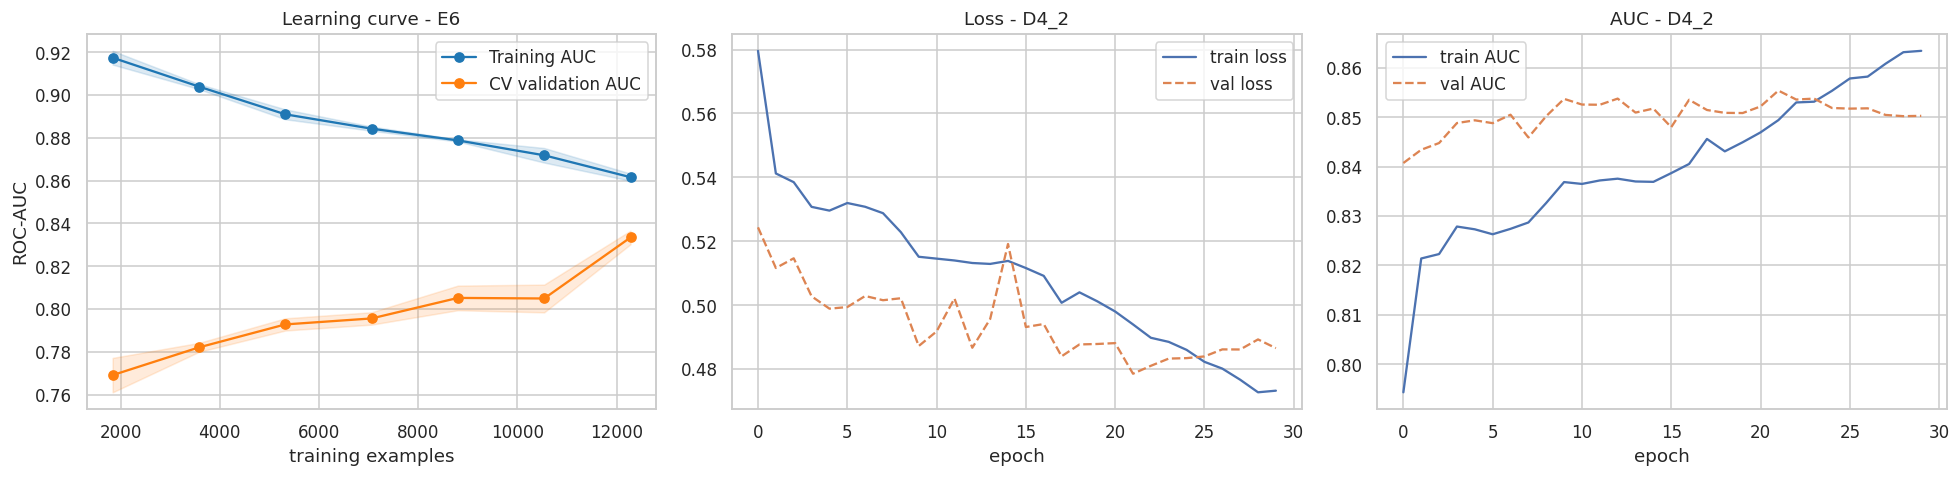

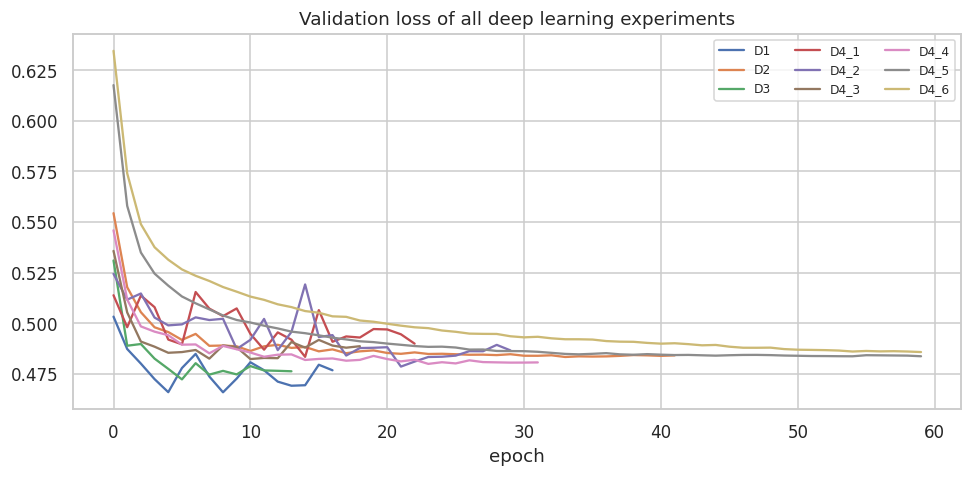

,ID,Model,Train AUC,Val AUC,Gap (train-val)
2,E3,Random Forest (default),1.0000,0.8464,0.1536
3,E4,Random Forest (tuned),0.9432,0.8470,0.0963
4,E5,Hist. Gradient Boosting (default),0.8907,0.8505,0.0402
16,D4_3,"MLP sweep lr=0.001, dropout=0.2",0.8682,0.8523,0.0158
12,D2,MLP regularised (BN+Dropout+L2),0.8647,0.8511,0.0136
13,D3,Residual MLP (Functional API),0.8594,0.8474,0.0120
11,D1,MLP baseline (Sequential),0.8599,0.8493,0.0107
18,D4_5,"MLP sweep lr=0.0001, dropout=0.2",0.8613,0.8513,0.0100
15,D4_2,"MLP sweep lr=0.01, dropout=0.4",0.8643,0.8553,0.0089
17,D4_4,"MLP sweep lr=0.001, dropout=0.4",0.8614,0.8528,0.0085


In [21]:
best_pipe = clone(STORE[best_ml_id]["model"])
sizes, tr_s, va_s = learning_curve(best_pipe, X_train, y_train, groups=g_train, cv=GroupKFold(3), scoring="roc_auc",
                                   train_sizes=np.linspace(0.15, 1.0, 5 if FAST_MODE else 7), n_jobs=1, random_state=SEED)
ncols = 3 if best_dl_id else 1
fig, ax = plt.subplots(1, ncols, figsize=(6 * ncols, 4.5))
ax = np.atleast_1d(ax)
for s, c, lab in [(tr_s, "#1f77b4", "Training AUC"), (va_s, "#ff7f0e", "CV validation AUC")]:
    ax[0].plot(sizes, s.mean(1), "o-", color=c, label=lab); ax[0].fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=c, alpha=.15)
ax[0].set_title(f"Learning curve - {best_ml_id}"); ax[0].set_xlabel("training examples"); ax[0].set_ylabel("ROC-AUC"); ax[0].legend()
if best_dl_id:
    h = HISTORIES[best_dl_id]
    ax[1].plot(h["loss"], label="train loss"); ax[1].plot(h["val_loss"], "--", label="val loss"); ax[1].set_title(f"Loss - {best_dl_id}"); ax[1].set_xlabel("epoch"); ax[1].legend()
    ax[2].plot(h["auc"], label="train AUC"); ax[2].plot(h["val_auc"], "--", label="val AUC"); ax[2].set_title(f"AUC - {best_dl_id}"); ax[2].set_xlabel("epoch"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/learning_curves.png", dpi=200); plt.show()

# Compare all deep runs' validation loss (shows effect of lr / regularisation)
if HISTORIES:
    plt.figure(figsize=(9, 4.5))
    for k, h in HISTORIES.items(): plt.plot(h["val_loss"], label=k)
    plt.title("Validation loss of all deep learning experiments"); plt.xlabel("epoch"); plt.legend(ncol=3, fontsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/dl_val_loss_all.png", dpi=200); plt.show()

gap = results_df[results_df["Main"]][["ID", "Model", "Train AUC", "Val AUC", "Gap (train-val)"]]
display(gap.sort_values("Gap (train-val)", ascending=False))

**Interpretation.**
* **E6 learning curve:** training AUC falls from 0.92 to 0.86 and cross-validated AUC rises from 0.77 to 0.83 as the training set grows from about 1,800 to 12,300 records. The gap is still closing and the validation curve is still rising at the right edge, so the model is not saturated — more training data would likely help, which matters for any institution building its own version.
* **D4_2 loss and AUC:** validation loss is noisy, with a spike near epoch 14, because a learning rate of 1e-2 takes large steps. Validation loss sits below training loss for most of training because the training loss includes class weights, L2 and dropout. In the AUC panel, training AUC overtakes validation AUC after about epoch 23 while validation AUC flattens near 0.85 — the start of over-fitting, which early stopping caught by restoring the best weights.
* **All networks:** the lr 1e-2 runs (D4_1, D4_2) have the noisiest validation loss, the lr 1e-4 runs (D4_5, D4_6) descend slowly and use all 60 epochs, and the unregularised D1 reaches its lowest loss within about 5 epochs and then worsens, the clearest sign of over-fitting among the networks.

## 15. Confusion matrices, ROC and precision–recall curves
Confusion matrices use the validation-tuned threshold. The ROC and PR curves compare the best traditional and best deep model (and the logistic baseline) on the held-out test set.

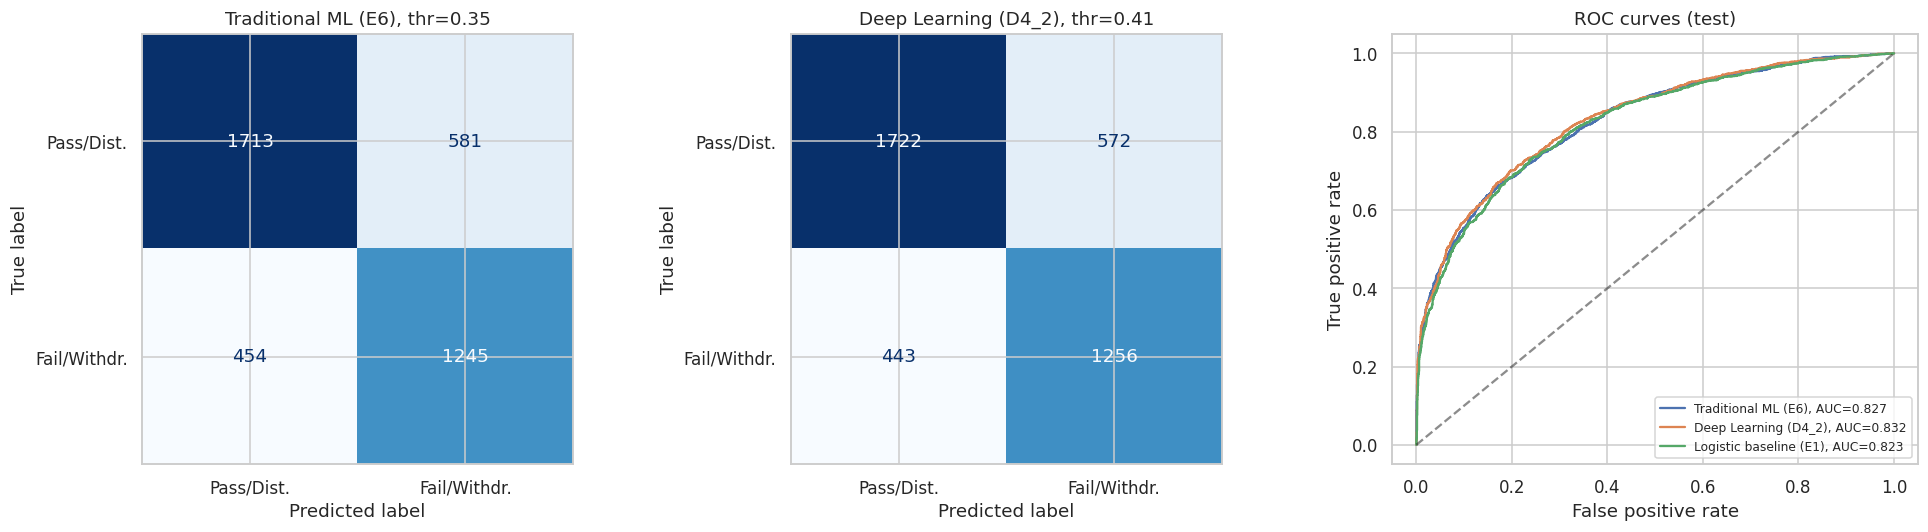

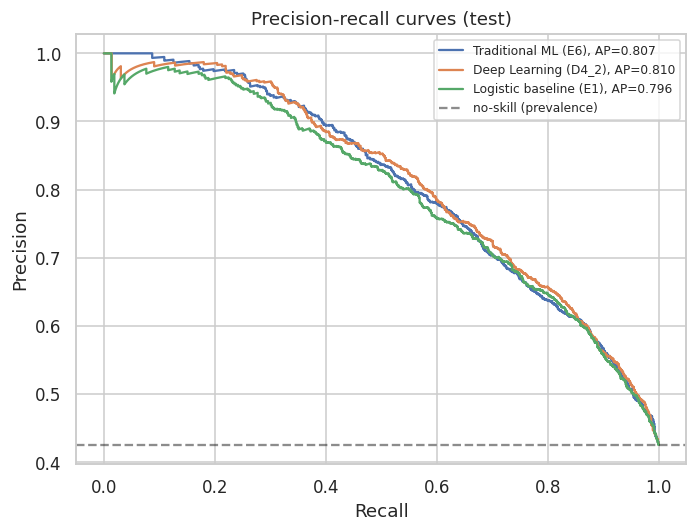

In [22]:
fig, ax = plt.subplots(1, len(FINAL) + 1, figsize=(6 * (len(FINAL) + 1), 5))
for a, (k, v) in zip(ax, FINAL.items()):
    cm = confusion_matrix(y_test, (STORE[v]["p_test"] >= THR[k]).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Pass/Dist.", "Fail/Withdr."]).plot(ax=a, cmap="Blues", colorbar=False, values_format="d")
    a.set_title(f"{k} ({v}), thr={THR[k]:.2f}")
curves = {f"{k} ({v})": STORE[v]["p_test"] for k, v in FINAL.items()}
curves["Logistic baseline (E1)"] = STORE["E1"]["p_test"]
for lab, p in curves.items():
    fpr, tpr, _ = roc_curve(y_test, p); ax[-1].plot(fpr, tpr, label=f"{lab}, AUC={roc_auc_score(y_test, p):.3f}")
ax[-1].plot([0, 1], [0, 1], "k--", alpha=.5); ax[-1].set_title("ROC curves (test)"); ax[-1].set_xlabel("False positive rate"); ax[-1].set_ylabel("True positive rate"); ax[-1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/confusion_roc.png", dpi=200); plt.show()

plt.figure(figsize=(6.5, 5))
for lab, p in curves.items():
    pr, rc, _ = precision_recall_curve(y_test, p); plt.plot(rc, pr, label=f"{lab}, AP={average_precision_score(y_test, p):.3f}")
plt.axhline(y_test.mean(), color="k", ls="--", alpha=.5, label="no-skill (prevalence)")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-recall curves (test)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/pr_curves.png", dpi=200); plt.show()

**Interpretation.** At its tuned threshold, E6 finds 1,245 of 1,699 at-risk test students (73 %) and raises 581 false alarms among 2,294 students who passed; D4_2 finds 1,256 with 572 false alarms. The two confusion matrices differ by only 11 students. The ROC curves of E6 (0.827), D4_2 (0.832) and even the logistic baseline (0.823) almost overlap. In practice, about one in three flagged students would be a false alarm. For a light-touch intervention such as an automated check-in message that is acceptable; for one-to-one tutoring, the threshold would need to rise, trading recall for precision along the PR curve.

## 16. Error analysis and feature importance
Which students does the best traditional model miss? We compute the false-negative rate (at-risk students predicted safe) and false-positive rate by module, age band and engagement level, and measure which features matter via permutation importance on the validation set.


--- by code_module ---


,n,at-risk rate,FN rate (missed at-risk),FP rate (false alarms)
code_module,,,,
AAA,109,0.202,0.455,0.126
BBB,934,0.414,0.302,0.252
CCC,513,0.519,0.184,0.287
DDD,752,0.496,0.204,0.314
EEE,382,0.306,0.333,0.155
FFF,946,0.424,0.264,0.262
GGG,357,0.373,0.429,0.259



--- by age_band ---


,n,at-risk rate,FN rate (missed at-risk),FP rate (false alarms)
age_band,,,,
0-35,2766,0.449,0.257,0.274
35-55,1196,0.376,0.298,0.214
55<=,31,0.226,0.143,0.167



--- by engagement ---


,n,at-risk rate,FN rate (missed at-risk),FP rate (false alarms)
engagement,,,,
Q1 lowest,999,0.644,0.103,0.497
Q2,998,0.456,0.240,0.365
Q3,998,0.367,0.418,0.203
Q4 highest,998,0.235,0.536,0.102



Share of true Withdrawn vs Fail students that the model flags:


,flagged rate
final_result,
Fail,0.758
Withdrawn,0.689


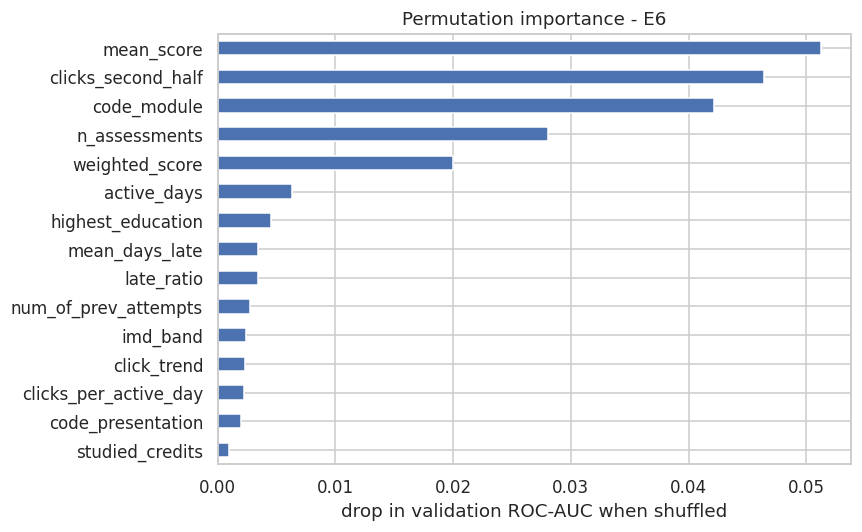

In [23]:
test_df = S["test"].copy()
test_df["p"] = STORE[best_ml_id]["p_test"]; test_df["pred"] = (test_df["p"] >= THR["Traditional ML"]).astype(int)
test_df["engagement"] = pd.qcut(test_df["total_clicks"].rank(method="first"), 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
def err_table(col):
    g = test_df.groupby(col, observed=True)
    return pd.DataFrame({"n": g.size(),
        "at-risk rate": g["at_risk"].mean().round(3),
        "FN rate (missed at-risk)": g.apply(lambda x: ((x["pred"] == 0) & (x["at_risk"] == 1)).sum() / max((x["at_risk"] == 1).sum(), 1)).round(3),
        "FP rate (false alarms)": g.apply(lambda x: ((x["pred"] == 1) & (x["at_risk"] == 0)).sum() / max((x["at_risk"] == 0).sum(), 1)).round(3)})
for c in ["code_module", "age_band", "engagement"]:
    print(f"\n--- by {c} ---"); display(err_table(c))
test_df["outcome_detail"] = test_df["final_result"]
print("\nShare of true Withdrawn vs Fail students that the model flags:")
display(test_df[test_df["at_risk"] == 1].groupby("final_result")["pred"].mean().round(3).rename("flagged rate"))

pi = permutation_importance(STORE[best_ml_id]["model"], X_val, y_val, scoring="roc_auc", n_repeats=3 if FAST_MODE else 8, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=ALL_FEATURES).sort_values().tail(15)
plt.figure(figsize=(8, 5)); imp.plot.barh(color="#4c72b0"); plt.xlabel("drop in validation ROC-AUC when shuffled")
plt.title(f"Permutation importance - {best_ml_id}"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/permutation_importance.png", dpi=200); plt.show()

**Interpretation.**
* **Engagement:** this is the clearest pattern. The miss rate rises from 10 % for the least engaged quarter to 54 % for the most engaged quarter, while false alarms fall from 50 % to 10 %. The model essentially learns "low activity = at risk", so active students who later fail or withdraw are hard to catch.
* **Modules:** misses are highest in AAA (45 %, but only 109 students) and GGG (43 %), and lowest in CCC (18 %) and DDD (20 %), where the at-risk rate is highest and the signal is stronger.
* **Age:** 35–55-year-olds are missed slightly more often (30 %) than under-35s (26 %).
* **Fail vs Withdrawn:** the model flags 76 % of eventual failures but only 69 % of eventual withdrawals. Students who left before day 60 were removed, so the remaining withdrawals happen later, often after events (work, family, health) that day-60 behaviour cannot reveal.
* **Feature importance:** mean assessment score, clicks in days 31–60, module, number of assessments submitted and weighted score dominate. Recent engagement (`clicks_second_half`) matters far more than total clicks, and demographics such as education and IMD band contribute little once behaviour is known.

## 17. Save the best models (Google Drive deliverables)
* **Traditional ML:** the complete fitted pipeline (preprocessing + model) as a `.joblib` file.
* **Deep learning:** the Keras model (`.keras`), a TensorFlow SavedModel export, and the fitted preprocessor needed to feed it.
* The raw dataset is zipped into the output folder (do **not** commit it to GitHub).

In [24]:
joblib.dump(STORE[best_ml_id]["model"], f"{OUT_DIR}/models/best_traditional_{best_ml_id}.joblib")
joblib.dump(dl_prep, f"{OUT_DIR}/models/dl_preprocessor.joblib")
joblib.dump({"cutoff_day": CUTOFF_DAY, "thresholds": THR, "features": ALL_FEATURES}, f"{OUT_DIR}/models/config.joblib")
if best_dl_id:
    STORE[best_dl_id]["model"].save(f"{OUT_DIR}/models/best_deep_{best_dl_id}.keras")
    try: STORE[best_dl_id]["model"].export(f"{OUT_DIR}/models/best_deep_{best_dl_id}_savedmodel")
    except Exception as e: print("SavedModel export skipped:", e)
if os.path.isdir(DATA_DIR):
    shutil.make_archive(f"{OUT_DIR}/oulad_raw_dataset", "zip", DATA_DIR)
for root, _, files in os.walk(OUT_DIR):
    if "wandb" in root or "tb_logs" in root: continue
    for f in files: print(os.path.join(root, f).replace(OUT_DIR, ""))

Saved artifact at '/content/drive/MyDrive/OULAD_ML_Final_Project/models/best_deep_D4_2_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 73), dtype=tf.float32, name='keras_tensor_85')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  136669855268112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136669855263504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136669858775312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136669858775120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136669855265232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136669855266384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136669858788752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136669858789520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136669858789136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136669858788944: TensorSpec(

**Interpretation.** The final models are E6 (`best_traditional_E6.joblib`, containing preprocessing and model together) and D4_2 (`best_deep_D4_2.keras` plus its SavedModel export), together with `dl_preprocessor.joblib`, `config.joblib` (cut-off day and tuned thresholds) and `oulad_raw_dataset.zip`. These six items are the Google Drive deliverables. The folder also contains files from earlier runs (`best_classical_gradient_boosting.joblib`, `best_deep_learning_mlp.keras`, the `D4_4` files and `evaluation_diagnostics_suite.png`), which are not produced by this version of the notebook and should not be submitted.

## 18. Conclusions
* **Paradigms are effectively tied.** The best network (D4_2) reached validation AUC 0.855 and test AUC 0.832; tuned gradient boosting (E6) reached 0.852 and 0.827. At validation-tuned thresholds their test recall is 0.739 and 0.733. These differences are smaller than the 0.008 spread among the network runs themselves, so neither paradigm clearly wins; boosting trains faster on a CPU and is easier to explain to advisers.
* **Features matter far more than algorithms.** Behavioural and assessment features raise AUC from 0.661 (demographics only) to 0.851, a gain more than ten times the spread across all main models.
* **Day 60 is a sensible horizon.** Moving from day 30 to 60 adds 0.056 AUC; moving on to day 90 adds only 0.014, while leaving less time to act.
* **Main weakness:** highly engaged students who later fail or withdraw are often missed (54 % miss rate in the most engaged quarter), and late withdrawals are harder to catch than failures.
* **Limitations:** one UK university (2013–14), aggregated clicks only, a merged Fail/Withdraw label, and possible demographic bias. Results may not transfer to African institutions without local data.
* **Next steps:** sequence models on daily clicks, SHAP explanations for advisers, a fairness audit across groups, and validation on data from an African online programme.

## 19. Reproducibility checklist

* TensorFlow op determinism is enabled, so deep-learning results are repeatable on GPU.

## 19. Reproducibility checklist
* Seeds set (Python, NumPy, scikit-learn via `random_state`, TensorFlow via `keras.utils.set_random_seed`).
* Dependencies are in `requirements.txt` (install with `pip install -r requirements.txt`).
* Data: download the OULAD CSV files from the Open University (https://analyse.kmi.open.ac.uk/open-dataset) and place them in `DATA_DIR`.
* Run all cells top-to-bottom. For a fast smoke test set `FAST_MODE = True`.